In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [50]:
#Load a real-world dataset using Pandas
#import dataset:
dataset=pd.read_csv("Loan_Eligibility_Prediction.csv")
dataset.head()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [51]:
#Data preprocessing: 
#handle missing values  
dataset.isnull().sum()
print("\nTotal missing values:")
print(dataset.isnull().sum().sum())


Total missing values:
0


In [52]:
#remove duplicates:
df = dataset.drop_duplicates()

In [53]:
df

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,480,Male,Yes,2,Graduate,No,2947,1603.0,10,360,1,Urban,N
610,525,Male,No,0,Graduate,No,4680,2087.0,15,360,1,Semiurban,N
611,551,Male,Yes,2,Graduate,Yes,6633,0.0,25,360,0,Rural,N
612,552,Male,Yes,1,Not Graduate,No,2492,2375.0,30,360,1,Rural,Y


In [54]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Loan_Status']=le.fit_transform(df['Loan_Status'])
df['Gender']=le.fit_transform(df['Gender'])
df['Married']=le.fit_transform(df['Married'])
df['Self_Employed']=le.fit_transform(df['Self_Employed'])
df['Education']=le.fit_transform(df['Education'])
df['Property_Area']=le.fit_transform(df['Property_Area'])

In [55]:
df

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,0,0,0,0,0,2378,0.0,9,360,1,2,0
1,15,1,1,2,0,0,1299,1086.0,17,120,1,2,1
2,95,1,0,0,1,0,3620,0.0,25,120,1,1,1
3,134,1,1,0,0,1,3459,0.0,25,120,1,1,1
4,556,1,1,1,0,0,5468,1032.0,26,360,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,480,1,1,2,0,0,2947,1603.0,10,360,1,2,0
610,525,1,0,0,0,0,4680,2087.0,15,360,1,1,0
611,551,1,1,2,0,1,6633,0.0,25,360,0,0,0
612,552,1,1,1,1,0,2492,2375.0,30,360,1,0,1


In [56]:
df.mean()

Customer_ID            307.500000
Gender                   0.812704
Married                  0.649837
Dependents               0.856678
Education                0.218241
Self_Employed            0.148208
Applicant_Income      5403.459283
Coapplicant_Income    1621.245798
Loan_Amount            142.022801
Loan_Amount_Term       338.892508
Credit_History           0.850163
Property_Area            1.037459
Loan_Status              0.687296
dtype: float64

In [57]:
df.median()

Customer_ID            307.5
Gender                   1.0
Married                  1.0
Dependents               0.0
Education                0.0
Self_Employed            0.0
Applicant_Income      3812.5
Coapplicant_Income    1188.5
Loan_Amount            125.0
Loan_Amount_Term       360.0
Credit_History           1.0
Property_Area            1.0
Loan_Status              1.0
dtype: float64

In [58]:
df.mode()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,1.0,1.0,0.0,0.0,0.0,2500.0,0.0,120.0,360.0,1.0,1.0,1.0
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,610,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
610,611,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
611,612,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
612,613,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
df.describe()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,307.500000,0.812704,0.649837,0.856678,0.218241,0.148208,5403.459283,1621.245798,142.022801,338.892508,0.850163,1.037459,0.687296
std,177.390811,0.390467,0.477410,1.216651,0.413389,0.355596,6109.041673,2926.248369,87.083089,69.716355,0.357203,0.787482,0.463973
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000,0.000000,0.000000
25%,154.250000,1.000000,0.000000,0.000000,0.000000,0.000000,2877.500000,0.000000,98.000000,360.000000,1.000000,0.000000,0.000000
50%,307.500000,1.000000,1.000000,0.000000,0.000000,0.000000,3812.500000,1188.500000,125.000000,360.000000,1.000000,1.000000,1.000000
75%,460.750000,1.000000,1.000000,2.000000,0.000000,0.000000,5795.000000,2297.250000,164.750000,360.000000,1.000000,2.000000,1.000000
max,614.000000,1.000000,1.000000,4.000000,1.000000,1.000000,81000.000000,41667.000000,700.000000,480.000000,1.000000,2.000000,1.000000


In [60]:
df.std()

Customer_ID            177.390811
Gender                   0.390467
Married                  0.477410
Dependents               1.216651
Education                0.413389
Self_Employed            0.355596
Applicant_Income      6109.041673
Coapplicant_Income    2926.248369
Loan_Amount             87.083089
Loan_Amount_Term        69.716355
Credit_History           0.357203
Property_Area            0.787482
Loan_Status              0.463973
dtype: float64

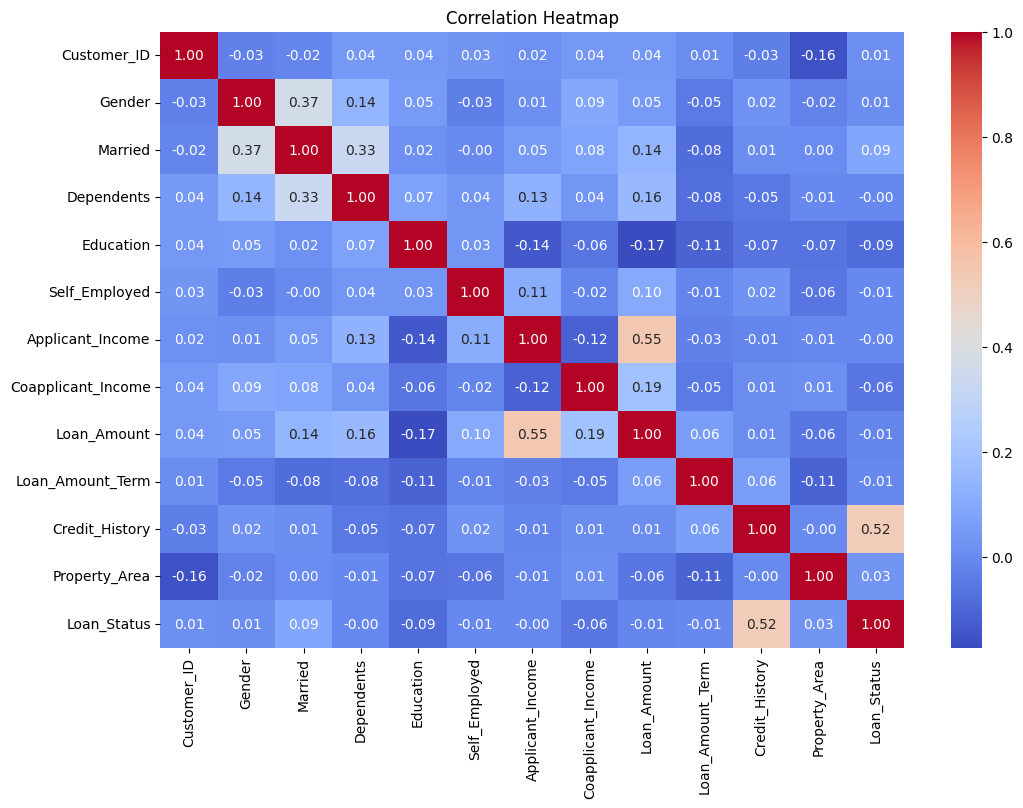

In [61]:
#correlation analysis 
import seaborn as sns
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [62]:
df.head(1)

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,0,0,0,0,0,2378,0.0,9,360,1,2,0


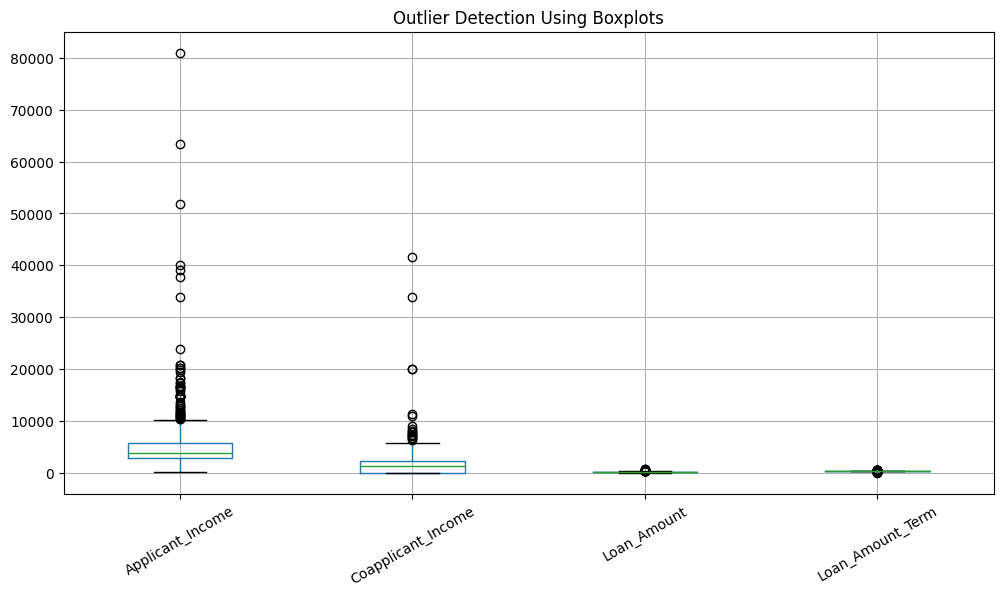

In [63]:
#outlier detection:
plt.figure(figsize=(12, 6))
numeric_features = [
    "Applicant_Income",
    "Coapplicant_Income",
    "Loan_Amount",
    "Loan_Amount_Term"
]

df[numeric_features].boxplot()

plt.title("Outlier Detection Using Boxplots")
plt.xticks(rotation=30)
plt.show()

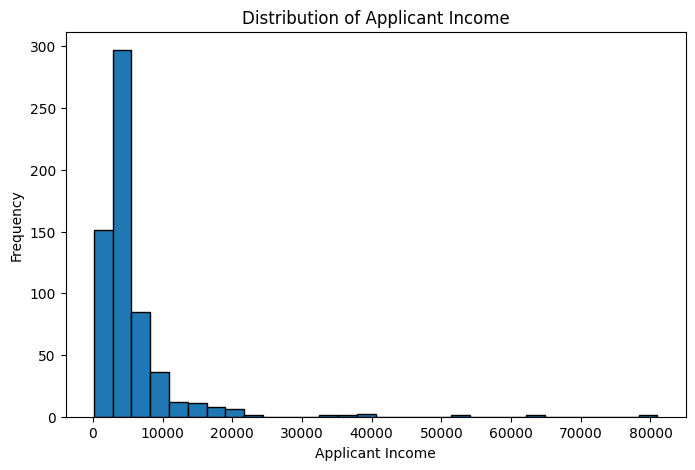

In [64]:
#histogram  
plt.figure(figsize=(8, 5))

plt.hist(
    df["Applicant_Income"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")

plt.show()

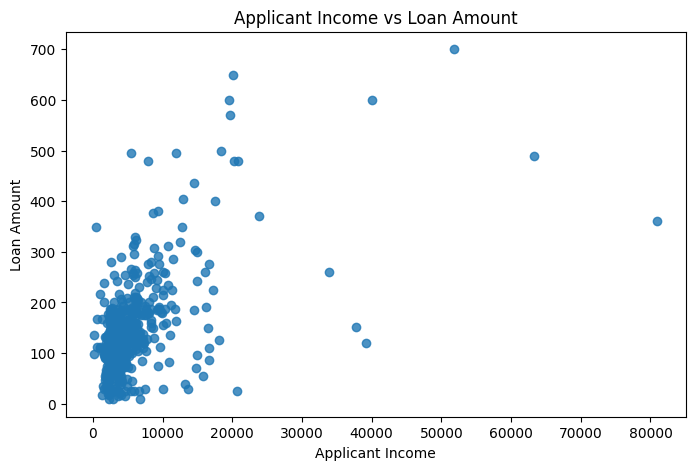

In [65]:
#scatter plot:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Applicant_Income"],
    df["Loan_Amount"],
    alpha=0.8
)

plt.title("Applicant Income vs Loan Amount")
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount")

plt.show()

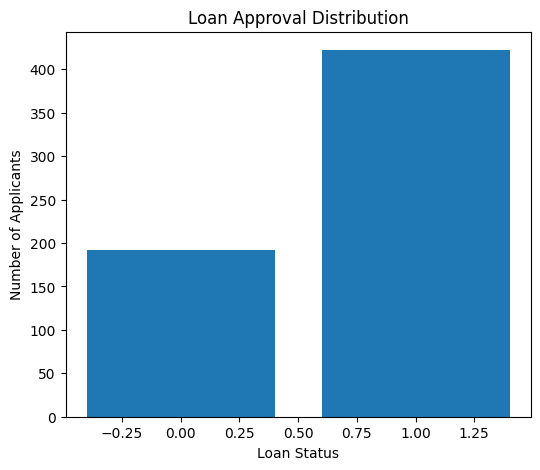

In [66]:
#BAR
loan_status_counts = df["Loan_Status"].value_counts()

plt.figure(figsize=(6, 5))

plt.bar(
    loan_status_counts.index,
    loan_status_counts.values
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

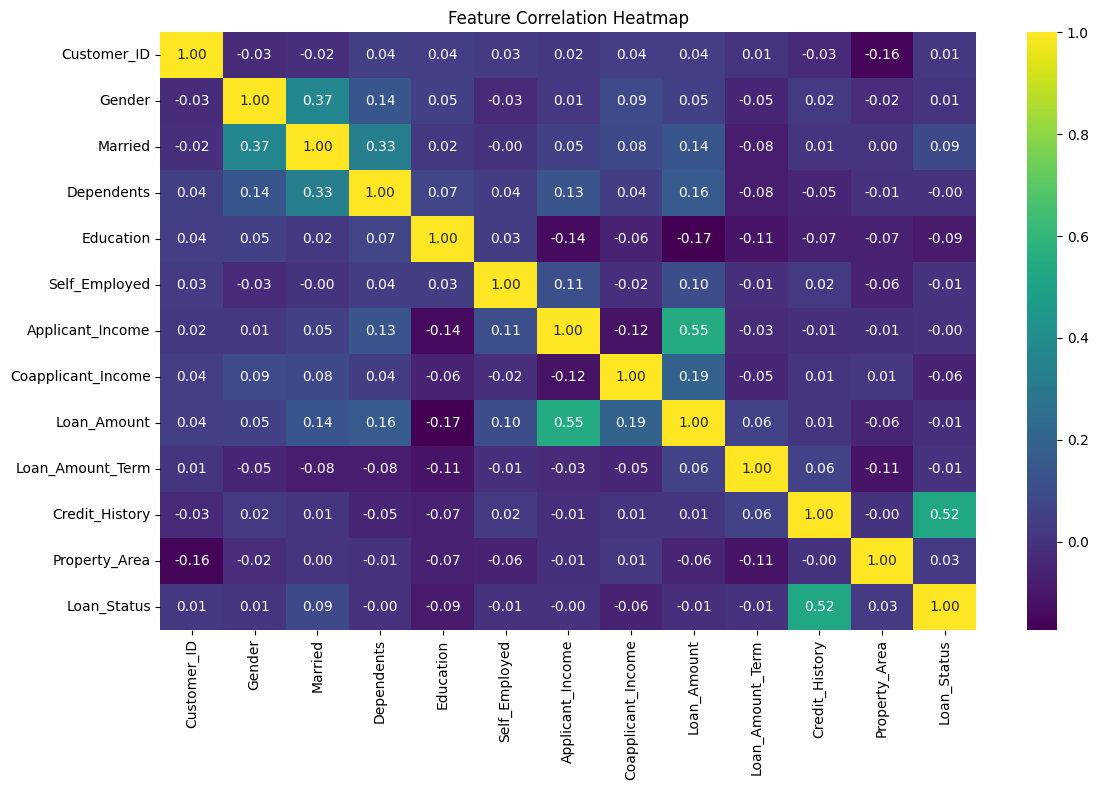

In [67]:
#Heatmap:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [68]:
df

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,0,0,0,0,0,2378,0.0,9,360,1,2,0
1,15,1,1,2,0,0,1299,1086.0,17,120,1,2,1
2,95,1,0,0,1,0,3620,0.0,25,120,1,1,1
3,134,1,1,0,0,1,3459,0.0,25,120,1,1,1
4,556,1,1,1,0,0,5468,1032.0,26,360,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,480,1,1,2,0,0,2947,1603.0,10,360,1,2,0
610,525,1,0,0,0,0,4680,2087.0,15,360,1,1,0
611,551,1,1,2,0,1,6633,0.0,25,360,0,0,0
612,552,1,1,1,1,0,2492,2375.0,30,360,1,0,1


In [69]:
#Remove unique values for better prediction:
df= df.drop(columns=[ "Customer_ID"])
df

,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,0,0,0,0,2378,0.0,9,360,1,2,0
1,1,1,2,0,0,1299,1086.0,17,120,1,2,1
2,1,0,0,1,0,3620,0.0,25,120,1,1,1
3,1,1,0,0,1,3459,0.0,25,120,1,1,1
4,1,1,1,0,0,5468,1032.0,26,360,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
609,1,1,2,0,0,2947,1603.0,10,360,1,2,0
610,1,0,0,0,0,4680,2087.0,15,360,1,1,0
611,1,1,2,0,1,6633,0.0,25,360,0,0,0
612,1,1,1,1,0,2492,2375.0,30,360,1,0,1


In [72]:
X=df.drop('Loan_Status',axis=1).values
X

array([[  0.,   0.,   0., ..., 360.,   1.,   2.],
       [  1.,   1.,   2., ..., 120.,   1.,   2.],
       [  1.,   0.,   0., ..., 120.,   1.,   1.],
       ...,
       [  1.,   1.,   2., ..., 360.,   0.,   0.],
       [  1.,   1.,   1., ..., 360.,   1.,   0.],
       [  1.,   1.,   0., ..., 180.,   1.,   2.]])

In [73]:
y=df['Loan_Status'].values
y

array([0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1,

In [74]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [76]:
#Feature Scaling:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [78]:
#Linear Regression:
#Training the simple linear regression model on the training set:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train)

LinearRegression()

In [86]:
#Predicting the test set results:
y_pred= regressor.predict(X_test_scaled)

In [89]:
from sklearn.metrics import mean_squared_error, r2_score
print('Coefficients:', regressor.coef_)
print('Intercept:', regressor.intercept_)
print('Mean squared error (MSE): %.2f'
% mean_squared_error(y_test, y_pred))
print('Coefficient of determination (R^2): %.2f'
% r2_score(y_test, y_pred))

Coefficients: [-0.01759812  0.05372261 -0.00171629 -0.02550861  0.00739849  0.01569214
 -0.02081145 -0.02787023 -0.0224376   0.25470164  0.01154398]
Intercept: 0.6761710794297352
Mean squared error (MSE): 0.16
Coefficient of determination (R^2): 0.18


In [91]:
#Logistic Regression :
#Training the logistic regression model on the training set:
from sklearn.linear_model import LogisticRegression
classifier=LogisticRegression()
classifier.fit(X_train,y_train)

C:\Users\Akash\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [97]:
y_pred_lr= classifier.predict(X_test_scaled)

In [98]:
#Making the Confusion Matrix:
from sklearn.metrics import confusion_matrix, accuracy_score
cm=confusion_matrix(y_test,y_pred)
print(cm)
print("Testing accuracy:",accuracy_score(y_test,y_pred_lr))

[[13 20]
 [ 6 84]]
Testing accuracy: 0.7886178861788617


In [99]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       0.68      0.39      0.50        33
           1       0.81      0.93      0.87        90

    accuracy                           0.79       123
   macro avg       0.75      0.66      0.68       123
weighted avg       0.77      0.79      0.77       123



In [100]:
#K-Nearest Neighbors (KNN):
#Training the K-NN model on the Training set:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=2)
classifier.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [101]:
y_pred_knn = classifier.predict(X_test_scaled)

In [102]:
#Confusion Matrix:
from sklearn.metrics import confusion_matrix,accuracy_score

cm=confusion_matrix(y_test,y_pred_knn)
print(cm)
print("Testing Accuracy:",accuracy_score(y_test,y_pred_knn))

[[13 20]
 [ 5 85]]
Testing Accuracy: 0.7967479674796748


In [103]:
from sklearn import metrics
from sklearn.metrics import classification_report
#train data
y_pred_train=classifier.predict(X_train_scaled)
print("Traing Accuracy:",metrics.accuracy_score(y_train,y_pred_train))
print(classification_report(y_train,y_pred_train))

Traing Accuracy: 0.8126272912423625
              precision    recall  f1-score   support

           0       0.87      0.50      0.63       159
           1       0.80      0.96      0.87       332

    accuracy                           0.81       491
   macro avg       0.83      0.73      0.75       491
weighted avg       0.82      0.81      0.80       491



In [104]:
#Support Vector Machine (SVM) :
#Training the SVM model on the training set:
#without scaling
from sklearn.svm import SVC
classifier= SVC(kernel= 'linear', random_state=0)
classifier.fit(X_train,y_train)

SVC(kernel='linear', random_state=0)

In [105]:
#Making the Confusion Matrix:
from sklearn.metrics import confusion_matrix, accuracy_score
y_pred_svm=classifier.predict(X_test)
cm=confusion_matrix(y_test,y_pred_svm)
print(cm)
print("Testing accuracy:",accuracy_score(y_test,y_pred_svm))

[[13 20]
 [ 4 86]]
Testing accuracy: 0.8048780487804879


In [106]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           0       0.76      0.39      0.52        33
           1       0.81      0.96      0.88        90

    accuracy                           0.80       123
   macro avg       0.79      0.67      0.70       123
weighted avg       0.80      0.80      0.78       123



In [112]:
#Naive Bayes:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train_scaled,y_train)

GaussianNB()

In [113]:
y_pred_naive=classifier.predict(X_test_scaled)

In [114]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test,y_pred_naive)
print(cm)
accuracy_score(y_test,y_pred_naive)

[[14 19]
 [ 6 84]]


0.7967479674796748

In [115]:
from sklearn import metrics
from sklearn.metrics import classification_report
#train data
y_pred_train=classifier.predict(X_train)
print(metrics.accuracy_score(y_train,y_pred_train))
print(classification_report(y_train,y_pred_train))

0.32382892057026474
              precision    recall  f1-score   support

           0       0.32      1.00      0.49       159
           1       0.00      0.00      0.00       332

    accuracy                           0.32       491
   macro avg       0.16      0.50      0.24       491
weighted avg       0.10      0.32      0.16       491



C:\Users\Akash\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Akash\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Akash\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [117]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

classifier=DecisionTreeClassifier()
classifier.fit(X_train,y_train)

y_pred_train=classifier.predict(X_train)

print(metrics.accuracy_score(y_train,y_pred_train))
print(classification_report(y_train,y_pred_train))

1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       159
           1       1.00      1.00      1.00       332

    accuracy                           1.00       491
   macro avg       1.00      1.00      1.00       491
weighted avg       1.00      1.00      1.00       491



In [118]:
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

classifier=RandomForestClassifier()
classifier.fit(X_train,y_train)

y_pred_train=classifier.predict(X_train)

print(metrics.accuracy_score(y_train,y_pred_train))
print(classification_report(y_train,y_pred_train))

1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       159
           1       1.00      1.00      1.00       332

    accuracy                           1.00       491
   macro avg       1.00      1.00      1.00       491
weighted avg       1.00      1.00      1.00       491



K-Means Clustering:
[0 0 1 0 0 1 0 1 1 1 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0
 0 0 1 1 0 1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 0 1 1 0 1 0 0 1 1 1 0 0 0 1 0 0 0 1 0 1 1 0
 1 0 1 0 0 1 0 1 0 0 1 1 1 0 1 0 0 1 0 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 0 0
 1 1 0 0 1 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0
 0 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 1 0 1 0 1 1 0 0 0 1 1 0 0 0 0 0 1 1
 0 1 0 1 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0
 1 0 1 0 1 0 0 1 1 0 1 1 1 0 0 0 0 1 0 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 0 1
 0 1 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 0 1 0 0
 1 1 0 0 1 0 1 1 0 1 0 0 1 0 0 1 1 1 0 0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0
 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 1 0 1 0 0
 1 1 0 0 0 0 1 0 1 0 0 1 0 1 1 1 1 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 1 1
 0 1 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 1 0 0 0
 0 1 

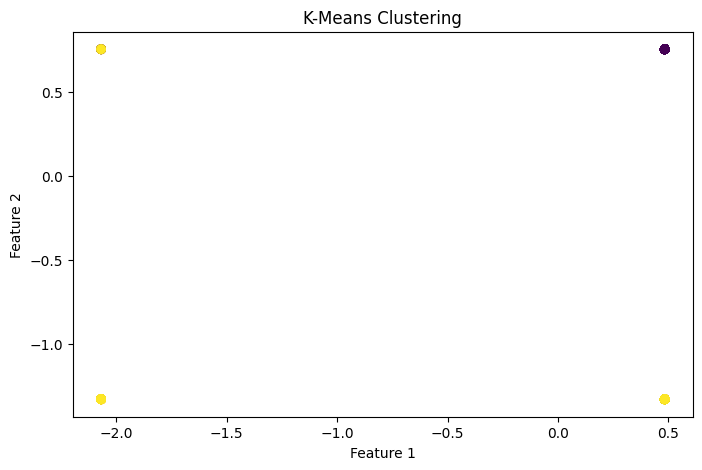

In [121]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_train_scaled)

print("K-Means Clustering:")
print(kmeans_labels)
plt.figure(figsize=(8,5))

plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=kmeans_labels
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()

Hierarchical Clustering:
[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0


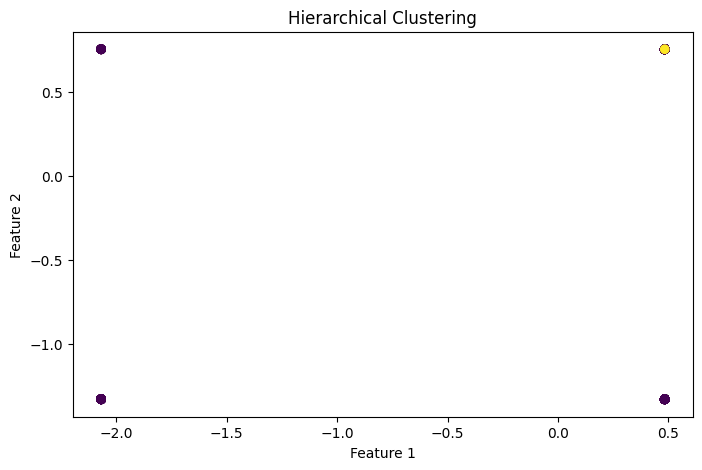

In [122]:
#hierarchical
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=2
)

hierarchical_labels = hierarchical.fit_predict(X_train_scaled)

print("Hierarchical Clustering:")
print(hierarchical_labels)
plt.figure(figsize=(8,5))

plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=hierarchical_labels
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Hierarchical Clustering")
plt.show()

In [123]:
#PCA:
#Apply PCA
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

In [124]:
X_train[0].shape

(2,)

In [125]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [126]:
from sklearn.metrics import confusion_matrix, accuracy_score
y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[ 1 32]
 [ 0 90]]


0.7398373983739838

In [ ]:
#Compare performances of all algorithms and write conclusions:
The Loan Eligibility dataset was loaded using Pandas and checked for missing values, duplicates, and data types.
Missing values were handled using median for numerical data and mode for categorical data.
Duplicate records were removed and categorical data was converted into numerical form.
Data was normalized using StandardScaler to improve model performance.
EDA was performed using statistics, correlation analysis, and outlier detection.
Histograms, scatter plots, bar graphs, and heatmaps were used for visualization.
Logistic Regression, KNN, SVM, Naive Bayes, Decision Tree, and Random Forest were used for classification.
Linear Regression was used to predict Loan_Amount and evaluated using RMSE and R² score.
K-Means and Hierarchical Clustering were used to group similar applicants, and PCA was used for dimensionality reduction.
unsupervised learning:  
o K-Means Clustering  
o Hierarchical Clustering performs well.
Overall, the project demonstrates a complete machine learning system and helps identify the best model for loan eligibility prediction."